# Forelesning 5: Likninger og nullpunkter

<div class="bilde-hoyre" style="width:50%">

![Løselighet](bilder/solubility.png)

</div>


I dag skal vi

- repetere halveringsmetoden ved å lese og forklare kode
- utlede og programmere **Newtons metode**, og undersøke når den virker og når den feiler
- bruke metodene til å finne pH i en svak syre

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

## Repetisjon: Koffein i energidrikker (15 til 20 minutter)

Ifølge etiketten inneholder en energidrikk 32 mg koffein per 100 mL. To laboratorier, A og B, har analysert koffeininnholdet i **de samme seks boksene** med HPLC. Her er et utsnitt av datasettet:

| can | lab | caffeine_mg_100mL |
|---|---|---|
| 1 | A | 31.2 |
| 1 | B | 31.8 |
| 2 | A | 32.5 |
| 2 | B | 33.0 |
| ... | ... | ... |

In [4]:
data = pd.DataFrame({
    "can": [1, 2, 3, 4, 5, 6] * 2,
    "lab": ["A"] * 6 + ["B"] * 6,
    "caffeine_mg_100mL": [31.2, 32.5, 30.8, 31.9, 31.4, 32.0,
                          31.8, 33.0, 31.5, 32.5, 32.0, 32.7],
})
data

,can,lab,caffeine_mg_100mL
0,1,A,31.2
1,2,A,32.5
2,3,A,30.8
3,4,A,31.9
4,5,A,31.4
5,6,A,32.0
6,1,B,31.8
7,2,B,33.0
8,3,B,31.5
9,4,B,32.5


<div class="oppgave">

**Del a) Beskriv dataene.** Beregn antall målinger, gjennomsnitt, standardavvik (hint: "agg") og RSD for *hvert laboratorium* (hint: groupby). Er presisjonen omtrent lik i de to laboratoriene?

</div>

<div class="oppgave">

**Del b) Stemmer etiketten?** Bruk målingene fra laboratorium A. Beregn et 95 % konfidensintervall og utfør en passende t-test mot 32 mg/100 mL. Hva kan du konkludere, og hva kan du *ikke* konkludere?

</div>

<div class="oppgave">

**Del c) Er laboratoriene uenige?** Velg en t-test for å sammenlikne A og B, og begrunn valget. Er forskjellen mellom laboratoriene kjemisk viktig?

Tips: `data[data["lab"] == "B"].sort_values("can")` gir målingene i samme rekkefølge som boksene.

</div>

## Del 1: Likninger som nullpunktsproblemer

<div class="viktig">

Enhver likning $g(x) = h(x)$ kan skrives om til et **nullpunktsproblem**:

$$f(x) = g(x) - h(x) = 0$$

Mange likninger i kjemi har ingen analytisk løsning. Da finner vi nullpunktet numerisk, steg for steg.

</div>

### Eksempel: pH i 0,010 M eddiksyre
Vi kan kombinere følgende sammenhenger for å utlede en funksjon $f(h)$ som beskriver syre-base-likevekten for en svak syre, der $h = [\mathrm{H_3O^+}]$:

1. **Syrekonstanten** for en svak syre $\mathrm{HA}$:

   $$K_a = \frac{[\mathrm{H_3O^+}][\mathrm{A^-}]}{[\mathrm{HA}]}$$

2. **Massebalansen**, der $C$ er den totale konsentrasjonen av syren:

   $$C = [\mathrm{HA}] + [\mathrm{A^-}]$$

3. **Vannets ioneprodukt**:

   $$K_w = [\mathrm{H_3O^+}][\mathrm{OH^-}]$$

4. **Ladningsbalansen**, som sier at summen av positive og negative ladninger må være lik:

   $$[\mathrm{H_3O^+}] = [\mathrm{A^-}] + [\mathrm{OH^-}]$$

Ved å kombinere disse sammenhengene og samle alle ledd på én side får vi:

$$f(h) = h - \frac{C K_a}{h + K_a} - \frac{K_w}{h} = 0$$

pH finner vi der $f(h) = 0$. Det er lurt å plotte funksjonen først for å se hvor nullpunktet ligger, sånn ca:

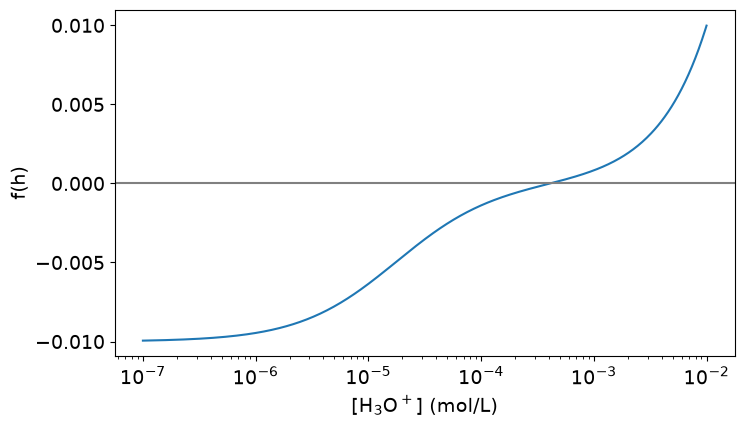

In [14]:
C = 0.010
Ka = 1.75e-5
Kw = 1.0e-14

# Definer f(h) her, med navnet charge_balance

h = np.logspace(-7, -2, 500)
plt.plot(??)
plt.xscale("log")
plt.axhline(0, color="gray")
plt.xlabel("[H$_3$O$^+$] (mol/L)")
plt.ylabel("f(h)")
plt.show()

<div class="diskuter">

**Diskuter:** Omtrent hvor ligger nullpunktet? Hvilket intervall ville du valgt for halveringsmetoden?

</div>

## Del 2: Repetisjon av halveringsmetoden

<div class="oppgave">

**Les og forklar:** Diskuter koden nedenfor i par. Én forklarer linje 1 til 8, den andre resten. Svar på disse spørsmålene sammen:

1. Hvorfor sjekker vi `f(a)*f(m) < 0`?
2. Hvorfor bruker vi en toleranse i stedet for `f(m) != 0`?
3. Hva skjer hvis `f(a)` og `f(b)` har samme fortegn?
4. Hvorfor har funksjonen et maksimalt antall iterasjoner?

</div>

In [ ]:
def halveringsmetoden(f, a, b, tol=1e-10, max_iter=100):
    i = 0
    m = (a + b) / 2

    while i < max_iter and abs(f(m)) > tol:
        if f(a) * f(m) < 0:
            b = m
        elif f(b) * f(m) < 0:
            a = m
        m = (a + b) / 2
        i = i + 1

    if i == max_iter:
        print("Maks antall iterasjoner er nådd.")
    return m, i

h_root, iterations = halveringsmetoden(charge_balance, 1e-7, 1e-2)
print(f"pH = {-np.log10(h_root):.3f} etter {iterations} iterasjoner")

<div class="viktig">

Halveringsmetoden er **robust**: Har vi et fortegnsskifte, finner den alltid et nullpunkt. Men den er **treg**, fordi intervallet bare halveres for hver iterasjon.

</div>

## Del 3: Newtons metode

<div class="bilde-hoyre" style="width:50%">

![Tangenter i Newtons metode](bilder/newton_tangent.png)

</div>

**Idé:** Vi starter i en gjetning $x_0$, tegner tangenten og ser hvor den krysser x-aksen. Der er neste gjetning.

Vi utleder metoden på tavla.

<div class="viktig">

**Newtons metode**

$$x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}$$

Vi gjentar til $|f(x_n)|$ er mindre enn en toleranse. Metoden trenger en **startverdi** og den **deriverte** $f'(x)$.

</div>

### Newtons metode i Python
Vi tester på $f(x) = x^2 - x - 2$, som har nullpunktet $x = 2$.

<div class="oppgave">

**Prøv selv:** Hvor fort går det? Legg til en teller `i`, og skriv ut `i`, `x` og `f(x)` for hver iterasjon. Hvor mange iterasjoner trengs? Hva skjer med antall riktige desimaler for hver iterasjon?

</div>

In [ ]:
x = 5
i = 0
while abs(f(x)) > 1e-8:
    x = x - f(x) / fder(x)
    ??
    print(??)

<div class="viktig">

Nær nullpunktet blir antall riktige desimaler omtrent **doblet** for hver iterasjon. Det kalles **kvadratisk konvergens**. Halveringsmetoden vinner bare omtrent én desimal for hver tredje iterasjon.

</div>

## Del 4: pH med Newtons metode

Nå bruker vi Newtons metode på eddiksyreproblemet.

<div class="oppgave">

**Prøv selv:**

1. Skriv funksjonen $f'(h) = 1 + \frac{C K_a}{(h + K_a)^2} + \frac{K_w}{h^2}$.
2. Bruk tilnærmingen $h_0 = \sqrt{K_a C}$ som startverdi. Hvor mange iterasjoner trenger Newtons metode? Sammenlikn med hva du tror halveringsmetoden ville brukt (sånn ca.).
</div>

<div class="diskuter">

**Diskuter:** Hvorfor er $\sqrt{K_a C}$ en god startverdi? Hvorfor er det en god idé å bruke kjemikunnskap til å velge startverdi?

</div>

## Del 5: Når feiler Newtons metode?

Vi prøver $f(x) = x^3 - 2x + 2$ med startverdi $x_0 = 0$.

<div class="diskuter">

**Tipp først:** Hva skjer? Programmet stopper etter seks iterasjoner, slik at det ikke går i evig løkke.

</div>

In [ ]:
def p(x):
    return x**3 - 2*x + 2

def pder(x):
    return 3*x**2 - 2

x = 0
for i in range(6):
    x = x - p(x) / pder(x)
    print(i + 1, x)

<div class="viktig">

Newtons metode kan feile når

- startverdien ligger for langt unna nullpunktet, slik at iterasjonene går i ring eller havner ved et annet nullpunkt
- $f'(x_n) = 0$, slik at tangenten er vannrett og vi deler på null
- funksjonen ikke har noe nullpunkt i nærheten

</div>

<div class="oppgave">

**Finn feilen:** Funksjonen nedenfor kan gå i evig løkke. Rett den slik at den har et maksimalt antall iterasjoner og gir en advarsel, slik som `halveringsmetoden`. Test den på `p` med startverdi 0 og startverdi −2.

</div>

In [ ]:
def newton(f, fder, x, tol=1e-10):
    while abs(f(x)) > tol:
        x = x - f(x) / fder(x)
    return x

<div class="diskuter">

**Diskuter:** Hva skjer hvis du bruker startverdi $x_0 = 0{,}5$ for $f(x) = x^2 - x - 2$? Hvorfor?

</div>

## Del 6: Ferdige løsere

`root_scalar` fra SciPy har både halveringsmetoden og Newtons metode. Resultatet forteller om metoden konvergerte, og hvor mange iterasjoner som trengtes.

## Hva bruker vi når?

<div class="viktig">

| Situasjon | Metode |
|---|---|
| Vi kjenner et intervall med fortegnsskifte | Halveringsmetoden |
| Vi har en god startverdi og kjenner den deriverte | Newtons metode |
| Allround god løser som itererer fort | Brents metode (brentq) |

Sjekk alltid at løsningen er kjemisk rimelig, for eksempel at konsentrasjonen er positiv.

</div>

__Oppgaver__:
1. Finn pH i 0,0250 M eddiksyre med Newtons metode. Sammenlikn med tilnærmingen $[\mathrm{H_3O^+}] \approx \sqrt{K_a C}$. Hvor stor er forskjellen?
2. Bruk `newton` på $f(x) = x^3 - 2x + 2$ med minst fem ulike startverdier. Forklar hvorfor metoden lykkes fra noen og feiler fra andre. Plott gjerne funksjonen.
3. Finn alle løsningene av $x^5 = 5x^3 + 3$. Plott først nullpunktsfunksjonen, og bruk deretter Newtons metode med ulike startverdier.
4. For likevekten A ⇌ B starter vi med 1,00 M A. Ved likevekt er $[\mathrm{B}] = x$ og $[\mathrm{A}] = 1 - x$, og $K = 3{,}5$. Skriv $K = [\mathrm{B}]/[\mathrm{A}]$ som et nullpunktsproblem uten brøk, løs det med Newtons metode og kontroller svaret analytisk.
5. Velg metode og begrunn valget: a) et fortegnsskifte mellom 2 og 3, men en derivert som er vanskelig å beregne; b) en god startverdi og en enkel derivert; c) mistanke om tre nullpunkter i $[-5, 5]$.